In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
from textblob import TextBlob

# Define the ticker and the time period
ticker = 'AAPL'
start_date = '2020-01-01'
end_date = '2023-01-01'

# Fetch the stock data
aapl_data = yf.download(ticker, start=start_date, end=end_date)


[*********************100%***********************]  1 of 1 completed


In [2]:
aapl_data.head()

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2020-01-02,72.333847,72.394055,71.091154,71.344024,135480400
2020-01-03,71.630638,72.389257,71.406666,71.563205,146322800
2020-01-06,72.201424,72.239958,70.503561,70.754028,118387200
2020-01-07,71.861832,72.466315,71.642674,72.211033,108872000
2020-01-08,73.017822,73.318862,71.565606,71.565606,132079200


In [3]:
aapl_data.columns

MultiIndex([( 'Close', 'AAPL'),
            (  'High', 'AAPL'),
            (   'Low', 'AAPL'),
            (  'Open', 'AAPL'),
            ('Volume', 'AAPL')],
           names=['Price', 'Ticker'])

In [4]:
aapl_data.columns = ['Close', 'High', 'Low', 'Open', 'Volume']

aapl_data.columns

Index(['Close', 'High', 'Low', 'Open', 'Volume'], dtype='str')

In [5]:
# Create a DataFrame with dates from the AAPL data
dates = aapl_data.index
text_data = pd.DataFrame(dates, columns=['Date'])


In [6]:
# Generate random headlines
headline_samples = [
    "AAPL hits record high",
    "Concerns over AAPL's future growth",
    "AAPL to unveil new product next month",
    "AAPL reports earnings that exceed forecasts",
    "Market downturn affects AAPL",
    "AAPL invests in renewable energy",
    "New AAPL CEO announced",
    "AAPL faces regulatory scrutiny",
    "AAPL rumored to acquire a tech startup",
    "AAPL's market share grows"
]

# Assign a random headline to each date
text_data['Headline'] = np.random.choice(headline_samples, size=len(text_data))

# Display the first few rows of the updated DataFrame
text_data.head()

,Date,Headline
0,2020-01-02,New AAPL CEO announced
1,2020-01-03,Market downturn affects AAPL
2,2020-01-06,Market downturn affects AAPL
3,2020-01-07,AAPL to unveil new product next month
4,2020-01-08,AAPL rumored to acquire a tech startup


In [7]:
text_data.head(30)

,Date,Headline
0,2020-01-02,New AAPL CEO announced
1,2020-01-03,Market downturn affects AAPL
2,2020-01-06,Market downturn affects AAPL
3,2020-01-07,AAPL to unveil new product next month
4,2020-01-08,AAPL rumored to acquire a tech startup
5,2020-01-09,AAPL hits record high
6,2020-01-10,AAPL faces regulatory scrutiny
7,2020-01-13,AAPL to unveil new product next month
8,2020-01-14,AAPL reports earnings that exceed forecasts
9,2020-01-15,AAPL's market share grows


In [8]:
def calculate_sentiment(text):
    return TextBlob(text).sentiment.polarity

# Applying the sentiment analysis function to your headlines
text_data['Sentiment'] = text_data['Headline'].apply(calculate_sentiment)

In [9]:
text_data.head(30)

,Date,Headline,Sentiment
0,2020-01-02,New AAPL CEO announced,0.136364
1,2020-01-03,Market downturn affects AAPL,0.000000
2,2020-01-06,Market downturn affects AAPL,0.000000
3,2020-01-07,AAPL to unveil new product next month,0.068182
4,2020-01-08,AAPL rumored to acquire a tech startup,0.000000
5,2020-01-09,AAPL hits record high,0.160000
6,2020-01-10,AAPL faces regulatory scrutiny,0.000000
7,2020-01-13,AAPL to unveil new product next month,0.068182
8,2020-01-14,AAPL reports earnings that exceed forecasts,0.000000
9,2020-01-15,AAPL's market share grows,0.000000


In [10]:
# Aligning sentiment scores with the stock closing prices on the same date
combined_data = text_data.set_index('Date').join(aapl_data['Close'])
combined_data.head()

,Headline,Sentiment,Close
Date,,,
2020-01-02,New AAPL CEO announced,0.136364,72.333847
2020-01-03,Market downturn affects AAPL,0.000000,71.630638
2020-01-06,Market downturn affects AAPL,0.000000,72.201424
2020-01-07,AAPL to unveil new product next month,0.068182,71.861832
2020-01-08,AAPL rumored to acquire a tech startup,0.000000,73.017822


The pct_change() is a pandas method that calculates the percentage change between the current and previous row.

for example:
(71.914825-72.620842) / 72.620842 = -0.009722


**Why It's Useful**

* Helps identify volatility or trends.

* Often used in financial modeling, risk analysis, or correlation with sentiment.




In [11]:
combined_data['Daily Returns'] = combined_data['Close'].pct_change()


In [12]:
combined_data.head()

,Headline,Sentiment,Close,Daily Returns
Date,,,,
2020-01-02,New AAPL CEO announced,0.136364,72.333847,NaN
2020-01-03,Market downturn affects AAPL,0.000000,71.630638,-0.009722
2020-01-06,Market downturn affects AAPL,0.000000,72.201424,0.007968
2020-01-07,AAPL to unveil new product next month,0.068182,71.861832,-0.004703
2020-01-08,AAPL rumored to acquire a tech startup,0.000000,73.017822,0.016086


# Pearson Correlation

What Pearson Correlation Measures linear relationship on continious variables
Range: from -1 to +1

+1: Perfect positive linear relationship

-1: Perfect negative linear relationship

 0: No linear relationship



A variable is continuous if:


*  It can take any value within a range (including decimals/fractions).

*  There are infinitely many possible values between any two numbers.



A variable is discrete if:


*   It takes distinct, separate values, usually integers or categories.
*   There are a finite or countably infinite number of values.
[link text](https://)

In [13]:
correlation = combined_data['Sentiment'].corr(combined_data['Daily Returns'])
print("Correlation between sentiment and daily stock returns:", correlation)


Correlation between sentiment and daily stock returns: 0.01305466299170471


In [14]:
correlation = combined_data['Sentiment'].corr(combined_data['Close'])
print("Correlation between sentiment and closing:", correlation)

Correlation between sentiment and closing: -0.002651851985672104


In [15]:
combined_data['Lagged Sentiment'] = combined_data['Sentiment'].shift(1)
correlation = combined_data['Lagged Sentiment'].corr(combined_data['Daily Returns'])
print("Correlation between sentiment and closing:", correlation)

Correlation between sentiment and closing: -0.04965558927645272


Summary
Weak or No Real Relationship: It’s possible sentiment really doesn’t move this stock — or the sentiment scoring isn’t accurate or relevant enough.

# Spearson Correlation

In [16]:
# Spearman correlation between sentiment and daily returns
spearman_corr_returns = combined_data['Sentiment'].corr(combined_data['Daily Returns'], method='spearman')
print("Spearman correlation (sentiment vs daily returns):", spearman_corr_returns)

Spearman correlation (sentiment vs daily returns): 0.0022418096026591925


In [17]:
# Spearman correlation between sentiment and closing prices
spearman_corr_close = combined_data['Sentiment'].corr(combined_data['Close'], method='spearman')
print("Spearman correlation (sentiment vs closing price):", spearman_corr_close)

Spearman correlation (sentiment vs closing price): 0.007832729002494777


# Kendall’s Tau


In [18]:
from scipy.stats import kendalltau

tau_returns, _ = kendalltau(combined_data['Sentiment'], combined_data['Daily Returns'])
tau_close, _ = kendalltau(combined_data['Sentiment'], combined_data['Close'])

print("Kendall's Tau (sentiment vs daily returns):", tau_returns)
print("Kendall's Tau (sentiment vs closing price):", tau_close)

Kendall's Tau (sentiment vs daily returns): nan
Kendall's Tau (sentiment vs closing price): 0.006425045410732572


In [19]:
print(combined_data['Sentiment'].isna().sum())
print(combined_data['Daily Returns'].isna().sum())
print(combined_data[['Sentiment', 'Daily Returns']].dropna().shape)

0
1
(755, 2)


In [20]:
from scipy.stats import kendalltau

# Drop rows with NaNs before computing
filtered = combined_data[['Sentiment', 'Daily Returns']].dropna()
tau_returns, _ = kendalltau(filtered['Sentiment'], filtered['Daily Returns'])
print("Fixed Kendall's Tau (sentiment vs daily returns):", tau_returns)


Fixed Kendall's Tau (sentiment vs daily returns): 0.00243161035226647


Interpretation
This value is:

Very close to 0

Negative, but not meaningfully so

It indicates no monotonic relationship between sentiment and daily stock returns, even when using the more conservative Kendall’s Tau method.

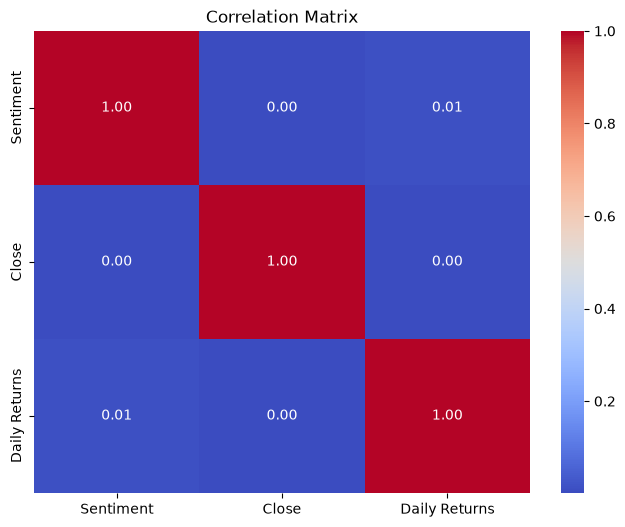

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select only the numeric columns you want to compare
corr_data = combined_data[['Sentiment', 'Close', 'Daily Returns']].dropna()

# Calculate correlation matrix
corr_matrix = corr_data.corr(method='pearson')  # You can also try 'spearman' or 'kendall'

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix')
plt.show()


In [22]:
from textblob import TextBlob

text1 = "This is the best day of my life."
text2 = "It is an average product."
text3 = "I hate everything about this."

print(TextBlob(text1).sentiment.polarity)  # ~0.8 (positive)
print(TextBlob(text2).sentiment.polarity)  # ~0.0 (neutral)
print(TextBlob(text3).sentiment.polarity)  # ~-1.0 (negative)


1.0
-0.15
-0.8
